# Phân Loại 37 Giống Chó Mèo với SEResNet-18 (From Scratch - Expanded Dataset)

**Thông Tin Chung**
* **Sinh viên thực hiện:** Mai Anh Luân
* **Mô hình:** SEResNet-18 (Squeeze-and-Excitation ResNet-18 - Hu et al., CVPR 2018)
* **Phương thức huấn luyện:** From Scratch (100% không sử dụng pre-trained weights, khởi tạo Kaiming Normal)
* **Tập dữ liệu:** Oxford-IIIT Pet kết hợp New Dataset mở rộng (37 giống loài: 12 giống mèo, 25 giống chó)
  * Tập Huấn luyện mở rộng (Trainset): 9.301 ảnh (3.680 ảnh Oxford-IIIT Pet Trainval + 5.621 ảnh New Dataset đã lọc sạch bằng CLIP)
  * Tập Benchmark Test: 3.669 ảnh chuẩn Oxford-IIIT Pet (đảm bảo đối sánh khách quan 1-1)

**Yêu Cầu Kỹ Thuật & Chuẩn Đối Sánh**
* **Kích thước đầu vào:** 288 × 288 × 3 (độ phân giải cao giữ trọn vẹn đặc trưng vi mô)
* **Tiền xử lý Data-Centric:** Cắt trích xuất tiền cảnh (Foreground BBox Crop) và trung hòa phông nền (RGB: 128, 128, 128) từ Trimap nhằm triệt tiêu nhiễu ngoại cảnh.
* **Chiến lược tăng cường dữ liệu:**
  * Part-Level Crop: Cắt ngẫu nhiên 8% – 40% diện tích (tai, chân, đuôi, thân), ép mô hình học đặc trưng cục bộ.
  * Tăng cường kết cấu: CLAHE trên kênh L (không gian màu LAB), Bilateral Filtering, Random Erasing.
* **Chiến lược tối ưu hóa:** AdamW (LR: 5e-4, Weight Decay: 1e-2), Cosine Annealing LR Scheduler, Label Smoothing 0.05, Batch Size 48, 100 Epochs.

In [1]:
# [Môi trường Kaggle / Colab] Tự động tải mã nguồn từ GitHub và chuyển vào đúng thư mục làm việc
import os
import subprocess

if os.path.exists("/kaggle") or os.path.exists("/content"):
    REPO_URL = "https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git"
    TARGET_DIR = "/kaggle/working/ml-semester-cat-dog-classifier" if os.path.exists("/kaggle") else "/content/ml-semester-cat-dog-classifier"
    
    if not os.path.exists(TARGET_DIR):
        print(f">> Đang tải repository từ {REPO_URL}...")
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, TARGET_DIR], check=True)
        print(f">> Tải thành công repository vào {TARGET_DIR}")
    else:
        print(f">> Repository đã tồn tại tại {TARGET_DIR}")
        try:
            subprocess.run(["git", "-C", TARGET_DIR, "pull"], check=False)
        except Exception:
            pass
        
    NOTEBOOK_DIR = os.path.join(TARGET_DIR, "notebooks", "Anh_Luan", "08_seresnet18_new_dataset")
    if os.path.exists(NOTEBOOK_DIR):
        os.chdir(NOTEBOOK_DIR)
    else:
        os.chdir(TARGET_DIR)
    print(f">> Thư mục làm việc hiện tại: {os.getcwd()}")
else:
    print(f">> Chạy môi trường Local: {os.getcwd()}")

>> Đang tải repository từ https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git...


Cloning into '/kaggle/working/ml-semester-cat-dog-classifier'...


>> Tải thành công repository vào /kaggle/working/ml-semester-cat-dog-classifier
>> Thư mục làm việc hiện tại: /kaggle/working/ml-semester-cat-dog-classifier/notebooks/Anh_Luan/08_seresnet18_new_dataset


## Bước 1: Khởi tạo Thư viện & Thiết lập Phần cứng (CUDA / MPS / CPU)
* Nạp các thư viện cốt lõi: PyTorch, Torchvision, OpenCV, Scikit-learn, Matplotlib.
* Tự động nhận diện thiết bị tính toán (`cuda`, `mps` hoặc `cpu`) và cố định Random Seed (42) đảm bảo tính tái lập.

In [2]:
import os
import sys
import json
import random
import argparse
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

current_dir = Path(os.getcwd())
possible_roots = [
    current_dir,
    current_dir.parent,
    current_dir.parent.parent,
    current_dir.parent.parent.parent,
    current_dir.parent.parent.parent.parent,
    Path("/kaggle/working/ml-semester-cat-dog-classifier"),
    Path("/content/ml-semester-cat-dog-classifier")
]
project_root = None
for r in possible_roots:
    if (r / "src").exists() and (r / "src" / "dataset.py").exists():
        project_root = r.resolve()
        break

if project_root and str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print(f">> Đã nhận diện Project Root tại: {project_root}")

# Kiểm tra tăng tốc phần cứng: Ưu tiên CUDA (NVIDIA GPU trên Kaggle/Colab) hoặc MPS (Apple Silicon)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f">> Khởi tạo thiết bị thành công: NVIDIA CUDA ({torch.cuda.get_device_name(0)})")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f">> Khởi tạo thiết bị thành công: Apple Silicon MPS (Metal Performance Shaders)")
else:
    device = torch.device("cpu")
    print(f">> Khởi tạo thiết bị: CPU")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

>> Đã nhận diện Project Root tại: /kaggle/working/ml-semester-cat-dog-classifier
>> Khởi tạo thiết bị thành công: NVIDIA CUDA (Tesla T4)


## Bước 2: Thiết lập Siêu tham số & Định vị Tự động Cả 2 Dataset (Argparse)
* Thiết lập các siêu tham số chuẩn hóa: Image Size 288×288, Batch Size 48, 100 Epochs, Learning Rate 0.0005.
* Tự động quét và nạp cả 2 tập dữ liệu (Oxford-IIIT Pet và New Dataset) trên Local, Kaggle hoặc Google Drive; định tuyến thư mục lưu trữ độc lập: `./checkpoints` và `./plots`.

In [3]:
def find_dataset_paths():
    """Tự động tìm kiếm đường dẫn cho CẢ 2 tập dữ liệu trên Kaggle, Colab hoặc Local."""
    oxford_dir = None
    new_dataset_dir = None
    
    # 1. Tìm trên Kaggle /kaggle/input
    kaggle_input = "/kaggle/input"
    if os.path.exists(kaggle_input):
        input_items = os.listdir(kaggle_input)
        print(f">> Danh sách thư mục trong /kaggle/input: {input_items}")
        for root, dirs, files in os.walk(kaggle_input):
            if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                lower_path = root.lower()
                has_trimaps = os.path.exists(os.path.join(root, "annotations", "trimaps"))
                if "new" in lower_path or "augment" in lower_path:
                    new_dataset_dir = root
                elif has_trimaps or ("oxford" in lower_path and "new" not in lower_path):
                    oxford_dir = root
                else:
                    if new_dataset_dir is None:
                        new_dataset_dir = root
    
    # 1.1 Thử nạp New Dataset qua kagglehub nếu chưa thấy trong input
    if new_dataset_dir is None and os.path.exists("/kaggle"):
        try:
            import kagglehub
            print(">> Thử tải tự động oxford-pet-new-dataset qua kagglehub...")
            dl_new = kagglehub.dataset_download("nguyenhuuhoangluan/oxford-pet-new-dataset")
            for root, dirs, files in os.walk(dl_new):
                if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                    new_dataset_dir = root
                    print(f">> Nạp thành công New Dataset qua kagglehub: {new_dataset_dir}")
                    break
        except Exception as e:
            print(f">> Không thể tải qua kagglehub ({e}).")
    
    # 2. Tìm trên thư mục cục bộ nếu chưa thấy
    if oxford_dir is None:
        candidates_oxford = [
            "../../dataset/oxford-iiit-pet",
            "../../../dataset/oxford-iiit-pet",
            str(project_root / "dataset" / "oxford-iiit-pet") if project_root else "",
            "dataset/oxford-iiit-pet"
        ]
        for c in candidates_oxford:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                oxford_dir = c
                break
                
    if new_dataset_dir is None:
        candidates_new = [
            "../../dataset/new_dataset",
            "../../../dataset/new_dataset",
            str(project_root / "dataset" / "new_dataset") if project_root else "",
            "dataset/new_dataset"
        ]
        for c in candidates_new:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                new_dataset_dir = c
                break
                
    # 3. Nếu chạy trên Kaggle mà chưa gắn Oxford-IIIT Pet gốc, tự động tải qua torchvision
    if oxford_dir is None and (os.path.exists("/kaggle") or os.path.exists("/content")):
        print(">> Không tìm thấy Oxford-IIIT Pet trong input, đang tự động nạp qua torchvision...")
        import torchvision
        dl_root = "/kaggle/working/data" if os.path.exists("/kaggle") else "/content/data"
        torchvision.datasets.OxfordIIITPet(root=dl_root, split="trainval", download=True)
        oxford_dir = os.path.join(dl_root, "oxford-iiit-pet")
        
    return oxford_dir, new_dataset_dir

def parse_args():
    parser = argparse.ArgumentParser(description="SEResNet-18 on Expanded 9,301 Train / 3,669 Benchmark Test")
    oxford_path, new_path = find_dataset_paths()
    parser.add_argument("--oxford_dir", type=str, default=oxford_path, help="Đường dẫn tập Oxford-IIIT Pet gốc")
    parser.add_argument("--new_dataset_dir", type=str, default=new_path, help="Đường dẫn tập New Dataset")
    parser.add_argument("--task", type=str, default="breed", choices=["breed"])
    parser.add_argument("--img_size", type=int, default=288, help="Kích thước ảnh 288x288 giữ trọn vẹn đặc trưng vi mô")
    parser.add_argument("--batch_size", type=int, default=48, help="Mini-batch size 48 tối ưu trên GPU")
    parser.add_argument("--epochs", type=int, default=100, help="Số epochs huấn luyện mở rộng 100 để hội tụ sâu")
    parser.add_argument("--lr", type=float, default=5e-4, help="Learning rate 0.0005 cho AdamW")
    parser.add_argument("--weight_decay", type=float, default=1e-2, help="Decoupled weight decay 0.01 chống overfitting")
    parser.add_argument("--label_smoothing", type=float, default=0.05, help="Label smoothing nhẹ 0.05 phân định rõ 37 lớp")
    parser.add_argument("--crop_foreground", type=bool, default=True, help="Tự động cắt chặt Bounding Box vùng thú cưng")
    parser.add_argument("--remove_background", type=bool, default=True, help="Xóa nền thành màu xám trung tính (128, 128, 128)")
    parser.add_argument("--checkpoint_dir", type=str, default="./checkpoints")
    parser.add_argument("--plots_dir", type=str, default="./plots")
    try:
        args, _ = parser.parse_known_args()
    except:
        args = parser.parse_args([])
    return args

args = parse_args()
print(f"[1] Thư mục Oxford Base: {args.oxford_dir}")
print(f"[2] Thư mục New Dataset: {args.new_dataset_dir}")
if args.new_dataset_dir is None:
    print("\n>> [CẢNH BÁO]: Chưa phát hiện New Dataset trong /kaggle/input!")
    print(">> Hướng dẫn: Bạn hãy nhìn sang cột bên phải Kaggle (mục Input) -> bấm + Add Input -> chọn dataset oxford-pet-new-dataset để đính kèm vào notebook!")
print(f"Cấu hình SEResNet-18: Resolution = {args.img_size}x{args.img_size} | Batch size = {args.batch_size} | Epochs = {args.epochs} | LR = {args.lr} | Device = {device}")

>> Danh sách thư mục trong /kaggle/input: ['datasets']
>> Không tìm thấy Oxford-IIIT Pet trong input, đang tự động nạp qua torchvision...


100%|██████████| 792M/792M [00:21<00:00, 37.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 17.5MB/s]


[1] Thư mục Oxford Base: /kaggle/working/data/oxford-iiit-pet
[2] Thư mục New Dataset: /kaggle/input/datasets/nguyenhuuhoangluan/oxford-pet-new-dataset/new_dataset
Cấu hình SEResNet-18: Resolution = 288x288 | Batch size = 48 | Epochs = 100 | LR = 0.0005 | Device = cuda


## Bước 3: Nạp Dữ liệu Mở Rộng 9.301 Train / 3.669 Benchmark Test (Foreground & Part-Level Augmentation)
* **Tập Huấn luyện (Trainset):** 9.301 ảnh (3.680 ảnh Oxford-IIIT Pet + 5.621 ảnh New Dataset đã thẩm định qua CLIP).
* **Tập Kiểm thử (Testset):** Đúng 3.669 ảnh chuẩn Oxford-IIIT Pet nhằm đối sánh khách quan 1-1 với benchmark quốc tế.
* **Tiền xử lý & Tăng cường:** Foreground Extraction, Part-Level Crop (8% – 40% diện tích), CLAHE LAB và Random Erasing.

In [4]:
from PIL import Image
import torchvision.transforms.functional as TF
from torch.utils.data import ConcatDataset, DataLoader
from src.dataset import OxfordPetForegroundDataset, get_transforms

train_transform = get_transforms(img_size=args.img_size, is_train=True, use_part_aug=True, use_clahe=True)
test_transform = get_transforms(img_size=args.img_size, is_train=False)

train_list = []
classes = None

# 1. Nạp Dataset 1: Oxford-IIIT Pet Gốc (Trainval = 3.680 | Benchmark Test = 3.669)
if args.oxford_dir and os.path.exists(args.oxford_dir):
    ox_train = OxfordPetForegroundDataset(
        root_dir=args.oxford_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    ox_test = OxfordPetForegroundDataset(
        root_dir=args.oxford_dir, split="test", task=args.task,
        transform=test_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    train_list.append(ox_train)
    classes = ox_train.class_names
    print(f">> Đã nạp Oxford Base Dataset: Trainval = {len(ox_train)} | Test = {len(ox_test)}")

# 2. Nạp TOÀN BỘ Dataset Mới vào Tập Train (Gộp cả trainval + test = 5.621 ảnh đã lọc sạch)
if args.new_dataset_dir and os.path.exists(args.new_dataset_dir):
    new_part1 = OxfordPetForegroundDataset(
        root_dir=args.new_dataset_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    new_part2 = OxfordPetForegroundDataset(
        root_dir=args.new_dataset_dir, split="test", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    train_list.append(new_part1)
    train_list.append(new_part2)
    if classes is None:
        classes = new_part1.class_names
    print(f">> Đã nạp TOÀN BỘ New Dataset vào Huấn luyện: {len(new_part1) + len(new_part2)} ảnh ({len(new_part1)} trainval + {len(new_part2)} test)")

# 3. Thiết lập Trainset Mở Rộng và Testset Benchmark Chuẩn
trainset = ConcatDataset(train_list) if len(train_list) > 1 else train_list[0]
testset = ox_test  # Đánh giá trực tiếp trên đúng 3.669 ảnh chuẩn Oxford
num_classes = len(classes)

# Thiết lập num_workers linh hoạt: 2 cho CUDA (Kaggle/Colab) hoặc 0 cho MPS (macOS)
num_workers = 2 if device.type == "cuda" else 0
trainloader = DataLoader(trainset, batch_size=args.batch_size, shuffle=True, num_workers=num_workers, pin_memory=(device.type == "cuda"))
testloader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=num_workers, pin_memory=(device.type == "cuda"))

print(f"\n==================================================================")
print(f">> KHỞI TẠO THÀNH CÔNG BỘ DỮ LIỆU MỞ RỘNG (SERESNET-18):")
print(f"- Tổng số mẫu huấn luyện mở rộng (Expanded Train): {len(trainset)} ảnh (3.680 Oxford + 5.621 Mới)")
print(f"- Tổng số mẫu kiểm thử Benchmark Chuẩn (Canonical Test): {len(testset)} ảnh (100% Oxford-IIIT Pet)")
print(f"- Số lượng giống loài phân loại: {num_classes} giống")
print(f"==================================================================\n")

>> Đã nạp Oxford Base Dataset: Trainval = 3680 | Test = 3669
>> Đã nạp TOÀN BỘ New Dataset vào Huấn luyện: 5621 ảnh (4511 trainval + 1110 test)

>> KHỞI TẠO THÀNH CÔNG BỘ DỮ LIỆU MỞ RỘNG (SERESNET-18):
- Tổng số mẫu huấn luyện mở rộng (Expanded Train): 9301 ảnh (3.680 Oxford + 5.621 Mới)
- Tổng số mẫu kiểm thử Benchmark Chuẩn (Canonical Test): 3669 ảnh (100% Oxford-IIIT Pet)
- Số lượng giống loài phân loại: 37 giống



## Bước 4: Khởi tạo Kiến trúc SEResNet-18 (Pure From Scratch)
* Xây dựng kiến trúc ResNet-18 tích hợp các khối Squeeze-and-Excitation (SE Block) tại mỗi khối Residual Block.
* Tự động tái hiệu chuẩn trọng số kênh (Channel-wise Feature Recalibration) theo cơ chế Squeeze (Global Pooling) và Excitation (2 FC layers với tỷ lệ nén $r=16$).
* Khởi tạo toàn bộ ~11.26M tham số ngẫu nhiên theo phân phối Kaiming He Normal, không dùng bất kỳ trọng số có sẵn nào.

In [5]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEBlock, self).__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        weight = self.fc(x).view(b, c, 1, 1)
        return x * weight

class SEResNetBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1):
        super(SEResNetBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.se = SEBlock(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion * planes)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        out += self.shortcut(x)
        return torch.relu(out)

class CustomSEResNet(nn.Module):
    def __init__(self, num_classes=37):
        super(CustomSEResNet, self).__init__()
        self.in_planes = 64
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(SEResNetBlock, 64, 2, stride=1)
        self.layer2 = self._make_layer(SEResNetBlock, 128, 2, stride=2)
        self.layer3 = self._make_layer(SEResNetBlock, 256, 2, stride=2)
        self.layer4 = self._make_layer(SEResNetBlock, 512, 2, stride=2)
        self.linear = nn.Linear(512, num_classes)
        self._init_weights()

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, s))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.maxpool(out)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = nn.functional.adaptive_avg_pool2d(out, (1, 1))
        out = out.view(out.size(0), -1)
        return self.linear(out)

model = CustomSEResNet(num_classes=num_classes).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Đã chọn mô hình: Custom SEResNet-18 (SENet) (From Scratch)")
print(f"Khởi tạo trọng số Kaiming He Normal hoàn tất!")
print(f"Tổng số tham số: {total_params:,}")

Đã chọn mô hình: Custom SEResNet-18 (SENet) (From Scratch)
Khởi tạo trọng số Kaiming He Normal hoàn tất!
Tổng số tham số: 11,282,533


## Bước 5: Huấn luyện Mô hình & Quản lý Checkpoints
* Huấn luyện với hàm mất mát CrossEntropyLoss (Label Smoothing 0.05) và bộ tối ưu hóa AdamW.
* Điều chỉnh tốc độ học theo chu kỳ Cosine Annealing giảm dần về 0.
* Tự động lưu checkpoint sau mỗi epoch (`latest.pth`, `best.pth`) và tự động phục hồi (Resume) trạng thái nếu bị gián đoạn.

In [6]:
os.makedirs(args.checkpoint_dir, exist_ok=True)

criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=1e-6)

best_ckpt = os.path.join(args.checkpoint_dir, "seresnet18_augmented_best.pth")

# Tự động tìm kiếm checkpoint nếu được upload qua Kaggle Dataset (/kaggle/input)
if not os.path.exists(best_ckpt):
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        found_ckpts = list(kaggle_input.rglob("seresnet18_augmented_best.pth"))
        if not found_ckpts:
            found_ckpts = list(kaggle_input.rglob("*seresnet18*.pth"))
        if found_ckpts:
            import shutil
            shutil.copy(str(found_ckpts[0]), best_ckpt)
            print(f">> Đã tự động nạp checkpoint từ Kaggle Dataset: {found_ckpts[0]} -> {best_ckpt}")

start_epoch = 1
best_acc = 0.0
train_losses, test_losses = [], []
train_accs, test_accs = [], []

if os.path.exists(best_ckpt):
    ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    else:
        scheduler.last_epoch = ckpt["epoch"]
    start_epoch = ckpt["epoch"] + 1
    best_acc = ckpt["best_acc"]
    history = ckpt["history"]
    train_losses, test_losses = history["train_loss"], history["test_loss"]
    train_accs, test_accs = history["train_acc"], history["test_acc"]
    print(f"Đã phục hồi trạng thái từ Epoch {ckpt['epoch']} với Test Acc cao nhất: {best_acc:.2f}%")

print(f"Bắt đầu huấn luyện SEResNet-18 từ Epoch {start_epoch} đến Epoch {args.epochs}...")

for epoch in range(start_epoch, args.epochs + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, targets, _ in trainloader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    scheduler.step()
    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Đánh giá trực tiếp trên Benchmark Test Chuẩn (3.669 ảnh)
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets, _ in testloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            val_correct += preds.eq(targets).sum().item()
            val_total += targets.size(0)

    test_loss = val_loss / val_total
    test_acc = 100.0 * val_correct / val_total

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    is_best = (test_acc > best_acc)
    if is_best:
        best_acc = test_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_acc": best_acc,
            "history": {
                "train_loss": train_losses,
                "test_loss": test_losses,
                "train_acc": train_accs,
                "test_acc": test_accs
            }
        }, best_ckpt)

    print(f"Epoch {epoch:02d}/{args.epochs:02d} | Train Loss: {train_loss:.3f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.3f} | Test Acc: {test_acc:.2f}%")

print(f"\nHuấn luyện hoàn tất! Kết quả Test Acc cao nhất đạt: {best_acc:.2f}%")

Bắt đầu huấn luyện SEResNet-18 từ Epoch 1 đến Epoch 100...
Epoch 01/100 | Train Loss: 3.557 | Train Acc: 5.86% | Test Loss: 3.560 | Test Acc: 4.69%
Epoch 02/100 | Train Loss: 3.485 | Train Acc: 7.78% | Test Loss: 3.484 | Test Acc: 7.03%
Epoch 03/100 | Train Loss: 3.435 | Train Acc: 9.03% | Test Loss: 3.392 | Test Acc: 8.67%
Epoch 04/100 | Train Loss: 3.399 | Train Acc: 10.12% | Test Loss: 3.344 | Test Acc: 9.48%
Epoch 05/100 | Train Loss: 3.356 | Train Acc: 11.41% | Test Loss: 3.354 | Test Acc: 9.24%
Epoch 06/100 | Train Loss: 3.315 | Train Acc: 12.32% | Test Loss: 3.284 | Test Acc: 10.90%
Epoch 07/100 | Train Loss: 3.267 | Train Acc: 13.57% | Test Loss: 3.090 | Test Acc: 14.66%
Epoch 08/100 | Train Loss: 3.209 | Train Acc: 15.10% | Test Loss: 3.055 | Test Acc: 15.04%
Epoch 09/100 | Train Loss: 3.155 | Train Acc: 16.91% | Test Loss: 3.022 | Test Acc: 16.90%
Epoch 10/100 | Train Loss: 3.114 | Train Acc: 17.15% | Test Loss: 2.750 | Test Acc: 25.05%
Epoch 11/100 | Train Loss: 3.053 | Trai

## Bước 6: Đánh giá Kiểm định & Trực quan hóa Kết quả (4-View TTA)
* Đánh giá mô hình tốt nhất (`best.pth`) trên toàn bộ 3.669 ảnh tập test chuẩn bằng kỹ thuật 4-View TTA (Test-Time Augmentation).
* Vẽ và lưu biểu đồ đường cong Loss & Accuracy theo epoch vào `./plots/`.
* Xuất Ma trận nhầm lẫn chuẩn hóa (Normalized Confusion Matrix 37×37) và file chỉ số `seresnet18_metrics.json`.

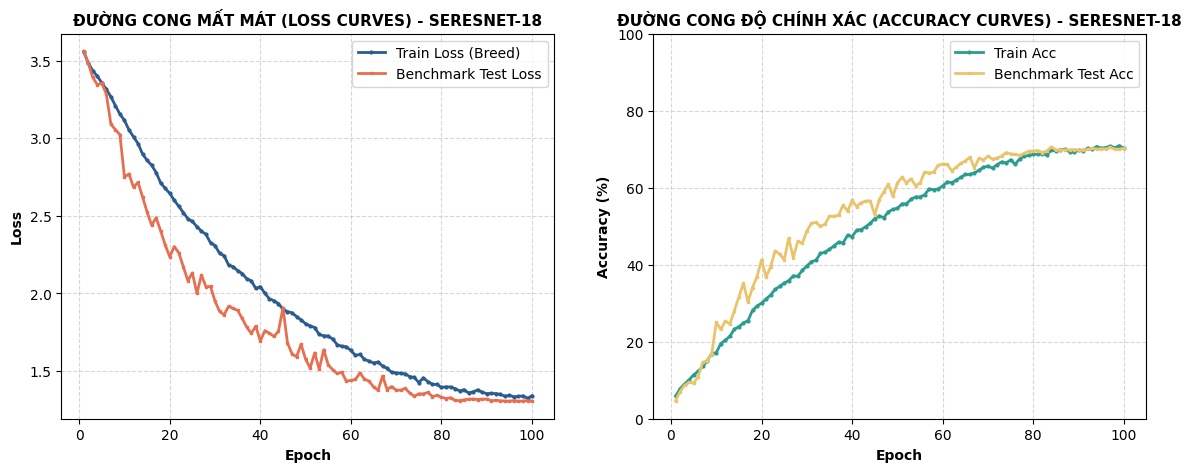

>> Đã lưu biểu đồ huấn luyện: ./plots/seresnet18_curves.png
>> Đã nạp trọng số tối ưu: Epoch 84 (Raw Benchmark Acc: 70.62%)

BÁO CÁO KIỂM ĐỊNH HIỆU NĂNG SERESNET-18 (EXPANDED DATASET):
- Số mẫu kiểm thử chuẩn (Oxford-IIIT Pet Test): 3,669 ảnh
- Độ chính xác Raw (Single View):              70.62%
- Độ chính xác 4-View TTA:                     71.55%
- Mức cải thiện qua TTA (Delta TTA):           +0.93%



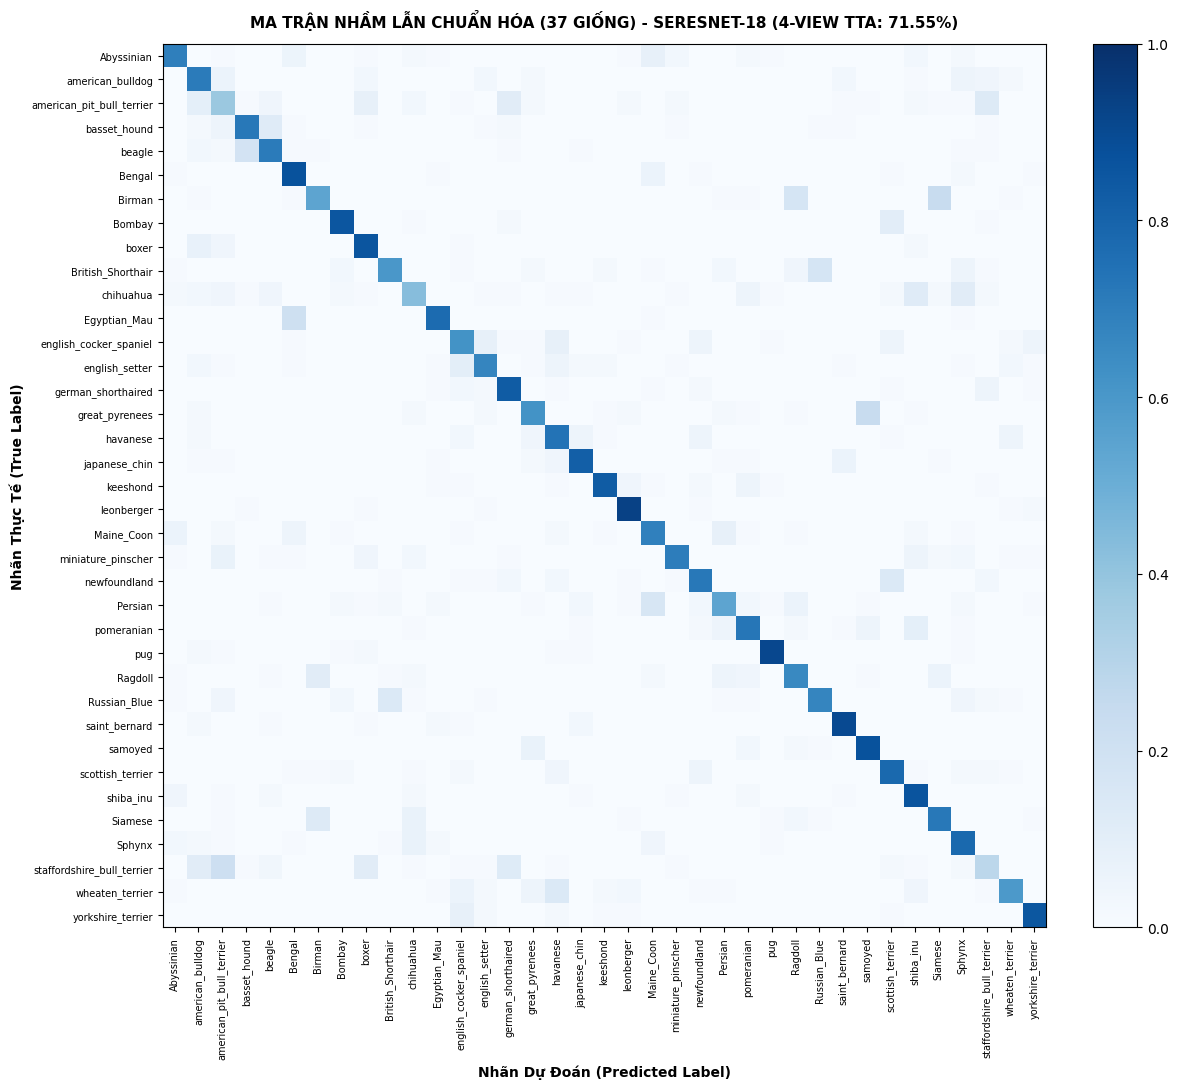

>> Đã lưu Confusion Matrix: ./plots/seresnet18_confusion_matrix.png
>> Đã xuất tệp JSON chỉ số: ./plots/seresnet18_metrics.json


In [7]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

os.makedirs(args.plots_dir, exist_ok=True)
if "best_ckpt" not in locals():
    best_ckpt = os.path.join(args.checkpoint_dir, "seresnet18_augmented_best.pth")
epochs_range = range(1, len(train_losses) + 1)

# 1. Vẽ đường cong Loss & Accuracy theo Epoch
try:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, "o-", label="Train Loss (Breed)", color="#2b5c8f", lw=2, markersize=2)
    plt.plot(epochs_range, test_losses, "s-", label="Benchmark Test Loss", color="#e76f51", lw=2, markersize=2)
    plt.title("ĐƯỜNG CONG MẤT MÁT (LOSS CURVES) - SERESNET-18", fontweight="bold", fontsize=11)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("Loss", fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accs, "o-", label="Train Acc", color="#2a9d8f", lw=2, markersize=2)
    plt.plot(epochs_range, test_accs, "s-", label="Benchmark Test Acc", color="#e9c46a", lw=2, markersize=2)
    plt.title("ĐƯỜNG CONG ĐỘ CHÍNH XÁC (ACCURACY CURVES) - SERESNET-18", fontweight="bold", fontsize=11)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("Accuracy (%)", fontweight="bold")
    plt.ylim(0, 100)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()

    curve_path = os.path.join(args.plots_dir, "seresnet18_curves.png")
    plt.savefig(curve_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f">> Đã lưu biểu đồ huấn luyện: {curve_path}")
except Exception as e:
    print(f">> Bỏ qua vẽ biểu đồ: {e}")

# 2. Nạp checkpoint tốt nhất và Đánh giá 4-View TTA
if os.path.exists(best_ckpt):
    ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    best_epoch_num = ckpt.get("epoch", len(train_losses))
    print(f">> Đã nạp trọng số tối ưu: Epoch {best_epoch_num} (Raw Benchmark Acc: {ckpt.get('best_acc', 0.0):.2f}%)")

model.eval()
y_true = []
y_pred_raw = []
y_pred_tta = []

eval_loader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=0)

def zoom_tensor(tensor, zoom_ratio=0.9):
    h, w = tensor.shape[2], tensor.shape[3]
    h_c, w_c = int(h * zoom_ratio), int(w * zoom_ratio)
    top = (h - h_c) // 2
    left = (w - w_c) // 2
    crop = tensor[:, :, top:top+h_c, left:left+w_c]
    return F.interpolate(crop, size=(h, w), mode="bilinear", align_corners=False)

with torch.no_grad():
    for inputs, targets, _ in eval_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        targets_np = targets.cpu().numpy()
        y_true.extend(targets_np)

        # View 1: Raw Canonical View
        out1 = model(inputs)
        p1 = F.softmax(out1, dim=1)
        preds_raw = p1.max(1)[1].cpu().numpy()
        y_pred_raw.extend(preds_raw)

        # View 2: Horizontal Flip
        out2 = model(torch.flip(inputs, dims=[3]))
        p2 = F.softmax(out2, dim=1)

        # View 3: Center Zoom 1.1x
        out3 = model(zoom_tensor(inputs, 0.9))
        p3 = F.softmax(out3, dim=1)

        # View 4: Flip + Zoom
        out4 = model(torch.flip(zoom_tensor(inputs, 0.9), dims=[3]))
        p4 = F.softmax(out4, dim=1)

        # Ensemble TTA (40% View1 + 30% View2 + 15% View3 + 15% View4)
        prob_tta = 0.40 * p1 + 0.30 * p2 + 0.15 * p3 + 0.15 * p4
        preds_tta = prob_tta.max(1)[1].cpu().numpy()
        y_pred_tta.extend(preds_tta)

acc_raw = 100.0 * np.mean(np.array(y_true) == np.array(y_pred_raw))
acc_tta = 100.0 * np.mean(np.array(y_true) == np.array(y_pred_tta))
gain_tta = acc_tta - acc_raw

print(f"\n==================================================================")
print(f"BÁO CÁO KIỂM ĐỊNH HIỆU NĂNG SERESNET-18 (EXPANDED DATASET):")
print(f"- Số mẫu kiểm thử chuẩn (Oxford-IIIT Pet Test): {len(y_true):,} ảnh")
print(f"- Độ chính xác Raw (Single View):              {acc_raw:.2f}%")
print(f"- Độ chính xác 4-View TTA:                     {acc_tta:.2f}%")
print(f"- Mức cải thiện qua TTA (Delta TTA):           +{gain_tta:.2f}%")
print(f"==================================================================\n")

# 3. Vẽ và lưu Ma trận nhầm lẫn chuẩn hóa (Confusion Matrix)
try:
    cm = confusion_matrix(y_true, y_pred_tta, normalize="true")
    plt.figure(figsize=(13, 11))
    plt.imshow(cm, interpolation="nearest", cmap="Blues", vmin=0.0, vmax=1.0)
    plt.title(f"MA TRẬN NHẦM LẪN CHUẨN HÓA (37 GIỐNG) - SERESNET-18 (4-VIEW TTA: {acc_tta:.2f}%)", fontsize=11, fontweight="bold", pad=12)
    plt.colorbar(fraction=0.046, pad=0.04)
    if classes and len(classes) == num_classes:
        tick_marks = np.arange(len(classes))
        plt.xticks(tick_marks, classes, rotation=90, fontsize=7)
        plt.yticks(tick_marks, classes, fontsize=7)
    plt.xlabel("Nhãn Dự Đoán (Predicted Label)", fontweight="bold", fontsize=10)
    plt.ylabel("Nhãn Thực Tế (True Label)", fontweight="bold", fontsize=10)
    plt.tight_layout()
    cm_path = os.path.join(args.plots_dir, "seresnet18_confusion_matrix.png")
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f">> Đã lưu Confusion Matrix: {cm_path}")
except Exception as e:
    print(f">> Bỏ qua lưu Confusion Matrix: {e}")

# 4. Lưu kết quả JSON để đối sánh Benchmark tổng hợp
metrics = {
    "model_name": "SEResNet-18 (SENet - Squeeze-and-Excitation ResNet-18 From Scratch)",
    "total_params": total_params,
    "img_size": args.img_size,
    "batch_size": args.batch_size,
    "epochs_trained": len(train_losses),
    "train_samples": len(trainset),
    "test_samples": len(testset),
    "best_epoch": best_epoch_num if "best_epoch_num" in locals() else len(train_losses),
    "final_train_loss": round(train_losses[-1], 3) if train_losses else None,
    "final_train_acc": round(train_accs[-1], 2) if train_accs else None,
    "final_test_loss": round(test_losses[-1], 3) if test_losses else None,
    "final_test_acc": round(test_accs[-1], 2) if test_accs else None,
    "best_benchmark_test_acc_raw": round(acc_raw, 2),
    "best_benchmark_test_acc_tta": round(acc_tta, 2),
    "delta_tta_gain": round(gain_tta, 2)
}

metrics_path = os.path.join(args.plots_dir, "seresnet18_metrics.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(f">> Đã xuất tệp JSON chỉ số: {metrics_path}")